# California Employment Trends by Industry (2019–2024)
**Author:** Tannaz Haghi · **Data:** U.S. Bureau of Labor Statistics (BLS), Current Employment Statistics (CES), State and Area

How did five California industries move through the COVID-19 shock and the 2022–2024 period?

In [1]:
import os
import sqlite3

import pandas as pd
import matplotlib.pyplot as plt
import requests

## 1. Configuration
Series IDs follow the BLS CES State and Area format: `SMU` + state `06` (California) + area `00000` (statewide) + 8-digit industry code + data type `01` (all employees, thousands). `SMU` = not seasonally adjusted.

In [2]:
# Read the API key from an environment variable. Never commit a key to the repo.
# In Terminal: export BLS_API_KEY="your_key_here"
API_KEY = os.environ.get("BLS_API_KEY")

series_ids = {
    "SMU06000007000000001": "Leisure & Hospitality",                          # 70000000
    "SMU06000005500000001": "Financial Activities",                           # 55000000
    "SMU06000006500000001": "Education & Health Services",                    # 65000000
    "SMU06000005000000001": "Information",                                    # 50000000
    "SMU06000006054000001": "Professional, Scientific & Technical Services",  # 60540000
}

## 2. Pull data from the BLS API (or load the saved copy)

In [3]:
def fetch_bls_series(series_id, start_year="2019", end_year="2024"):
    url = "https://api.bls.gov/publicAPI/v2/timeseries/data/"
    payload = {"seriesid": [series_id], "startyear": start_year,
               "endyear": end_year, "registrationkey": API_KEY}
    response = requests.post(url, json=payload, timeout=30)
    data = response.json()["Results"]["series"][0]["data"]
    df = pd.DataFrame(data)
    df["series_id"] = series_id
    return df

if API_KEY:
    raw_df = pd.concat([fetch_bls_series(sid) for sid in series_ids], ignore_index=True)
    raw_df.to_csv("data/raw_bls_data.csv", index=False)
    print("Fetched from BLS API and saved to data/raw_bls_data.csv")
else:
    raw_df = pd.read_csv("data/raw_bls_data.csv")
    print("No BLS_API_KEY set: loaded saved data from data/raw_bls_data.csv")

# Label industries from the series ID (single source of truth)
raw_df["industry"] = raw_df["series_id"].map(series_ids)
print(f"Rows: {len(raw_df)}")
raw_df.groupby("industry")["series_id"].first()

No BLS_API_KEY set: loaded saved data from data/raw_bls_data.csv
Rows: 360


industry
Education & Health Services                      SMU06000006500000001
Financial Activities                             SMU06000005500000001
Information                                      SMU06000005000000001
Leisure & Hospitality                            SMU06000007000000001
Professional, Scientific & Technical Services    SMU06000006054000001
Name: series_id, dtype: str

## 3. Clean

In [4]:
df = raw_df.copy()
df = df[df["period"].astype(str).str.startswith("M")]          # monthly rows only (drop M13 annual averages)
df["year"] = df["year"].astype(int)
df["month"] = df["period"].str.replace("M", "").astype(int)
df["employment"] = pd.to_numeric(df["value"], errors="coerce")  # thousands of jobs
df["date"] = pd.to_datetime(df[["year", "month"]].assign(day=1))
df = df[["date", "year", "month", "industry", "employment"]].dropna(subset=["employment"])

print(f"Rows after cleaning: {len(df)}")
print(f"Date range: {df['date'].min():%b %Y} to {df['date'].max():%b %Y}")
df.groupby("industry")["employment"].count()

Rows after cleaning: 360
Date range: Jan 2019 to Dec 2024


industry
Education & Health Services                      72
Financial Activities                             72
Information                                      72
Leisure & Hospitality                            72
Professional, Scientific & Technical Services    72
Name: employment, dtype: int64

## 4. Store in SQLite

In [5]:
conn = sqlite3.connect("ca_employment.db")
df.to_sql("employment", conn, if_exists="replace", index=False)
print("Saved to ca_employment.db")

Saved to ca_employment.db


## 5. Analysis (SQL)
### Q1. COVID impact: change in annual average employment, 2019 → 2020

In [6]:
q1 = """
SELECT
    industry,
    ROUND(AVG(CASE WHEN year = 2019 THEN employment END), 1) AS avg_2019,
    ROUND(AVG(CASE WHEN year = 2020 THEN employment END), 1) AS avg_2020,
    ROUND((AVG(CASE WHEN year = 2020 THEN employment END)
         - AVG(CASE WHEN year = 2019 THEN employment END))
         / AVG(CASE WHEN year = 2019 THEN employment END) * 100, 1) AS pct_change
FROM employment
GROUP BY industry
ORDER BY pct_change
"""
q1_result = pd.read_sql(q1, conn)
q1_result

,industry,avg_2019,avg_2020,pct_change
0,Leisure & Hospitality,2034.3,1481.8,-27.2
1,Information,567.2,540.5,-4.7
2,Financial Activities,840.0,816.4,-2.8
3,Education & Health Services,2806.8,2737.7,-2.5
4,"Professional, Scientific & Technical Services",1331.4,1301.6,-2.2


**Interpretation:** Leisure & Hospitality lost 27.2% of its jobs on an annual-average basis, more than 5 times the next-hardest-hit industry (Information, −4.7%). The other three industries fell 2–3%.

### Q2. Recovery: 2022 and 2024 employment vs. the 2019 baseline

In [7]:
q2 = """
WITH annual AS (
    SELECT industry, year, AVG(employment) AS avg_emp
    FROM employment
    GROUP BY industry, year
)
SELECT
    industry,
    ROUND(MAX(CASE WHEN year = 2019 THEN avg_emp END), 1) AS baseline_2019,
    ROUND(MAX(CASE WHEN year = 2022 THEN avg_emp END), 1) AS avg_2022,
    ROUND(MAX(CASE WHEN year = 2024 THEN avg_emp END), 1) AS avg_2024,
    ROUND((MAX(CASE WHEN year = 2024 THEN avg_emp END)
         / MAX(CASE WHEN year = 2019 THEN avg_emp END) - 1) * 100, 1) AS pct_vs_2019_in_2024,
    CASE WHEN MAX(CASE WHEN year = 2024 THEN avg_emp END)
            >= MAX(CASE WHEN year = 2019 THEN avg_emp END)
         THEN 'Above 2019' ELSE 'Below 2019' END AS status_2024
FROM annual
GROUP BY industry
ORDER BY pct_vs_2019_in_2024
"""
q2_result = pd.read_sql(q2, conn)
q2_result

,industry,baseline_2019,avg_2022,avg_2024,pct_vs_2019_in_2024,status_2024
0,Financial Activities,840.0,838.7,798.9,-4.9,Below 2019
1,Information,567.2,617.6,540.1,-4.8,Below 2019
2,Leisure & Hospitality,2034.3,1931.2,2016.6,-0.9,Below 2019
3,"Professional, Scientific & Technical Services",1331.4,1427.3,1405.3,5.6,Above 2019
4,Education & Health Services,2806.8,2933.7,3300.0,17.6,Above 2019


**Interpretation:** By 2024, three industries were still below their 2019 levels: Financial Activities (−4.9%), Information (−4.8%) and Leisure & Hospitality (−0.9%). Information had passed 2019 levels in 2022, then lost those gains. Education & Health Services ended 17.6% above 2019.

### Q3. Year-over-year change (LAG window function)

In [8]:
q3 = """
WITH annual AS (
    SELECT industry, year, AVG(employment) AS avg_emp
    FROM employment
    GROUP BY industry, year
)
SELECT
    industry,
    year,
    ROUND(avg_emp, 1) AS avg_employment,
    ROUND(avg_emp - LAG(avg_emp) OVER (PARTITION BY industry ORDER BY year), 1) AS yoy_change
FROM annual
ORDER BY industry, year
"""
q3_result = pd.read_sql(q3, conn)
q3_result

,industry,year,avg_employment,yoy_change
0,Education & Health Services,2019,2806.8,NaN
1,Education & Health Services,2020,2737.7,-69.2
2,Education & Health Services,2021,2817.7,80.0
3,Education & Health Services,2022,2933.7,116.0
4,Education & Health Services,2023,3104.6,171.0
5,Education & Health Services,2024,3300.0,195.3
6,Financial Activities,2019,840.0,NaN
7,Financial Activities,2020,816.4,-23.7
8,Financial Activities,2021,827.3,10.9
9,Financial Activities,2022,838.7,11.5


**Interpretation:** Education & Health Services grew every year from 2021 to 2024, and growth accelerated (+80K, +116K, +171K, +195K). Information grew strongly through 2022 (+48.8K), then fell in 2023 (−58.3K) and 2024 (−19.2K).

### Q4. Peak year and decline from peak (RANK window function)

In [9]:
q4 = """
WITH annual AS (
    SELECT industry, year, AVG(employment) AS avg_emp
    FROM employment
    GROUP BY industry, year
),
ranked AS (
    SELECT industry, year, avg_emp,
           RANK() OVER (PARTITION BY industry ORDER BY avg_emp DESC) AS rnk
    FROM annual
)
SELECT
    p.industry,
    p.year AS peak_year,
    ROUND(p.avg_emp, 1) AS peak_employment,
    ROUND(a.avg_emp, 1) AS avg_2024,
    ROUND((a.avg_emp / p.avg_emp - 1) * 100, 1) AS pct_change_peak_to_2024
FROM ranked p
JOIN annual a ON a.industry = p.industry AND a.year = 2024
WHERE p.rnk = 1
ORDER BY pct_change_peak_to_2024
"""
q4_result = pd.read_sql(q4, conn)
q4_result

,industry,peak_year,peak_employment,avg_2024,pct_change_peak_to_2024
0,Information,2022,617.6,540.1,-12.5
1,Financial Activities,2019,840.0,798.9,-4.9
2,"Professional, Scientific & Technical Services",2022,1427.3,1405.3,-1.5
3,Leisure & Hospitality,2019,2034.3,2016.6,-0.9
4,Education & Health Services,2024,3300.0,3300.0,0.0


**Interpretation:** Information fell 12.5% from its 2022 peak, the largest decline from peak of any industry. Professional, Scientific & Technical Services also peaked in 2022 and declined modestly (−1.5%). The timing is consistent with the 2023–2024 tech layoffs, but this analysis does not test the cause.

## 6. Visualizations

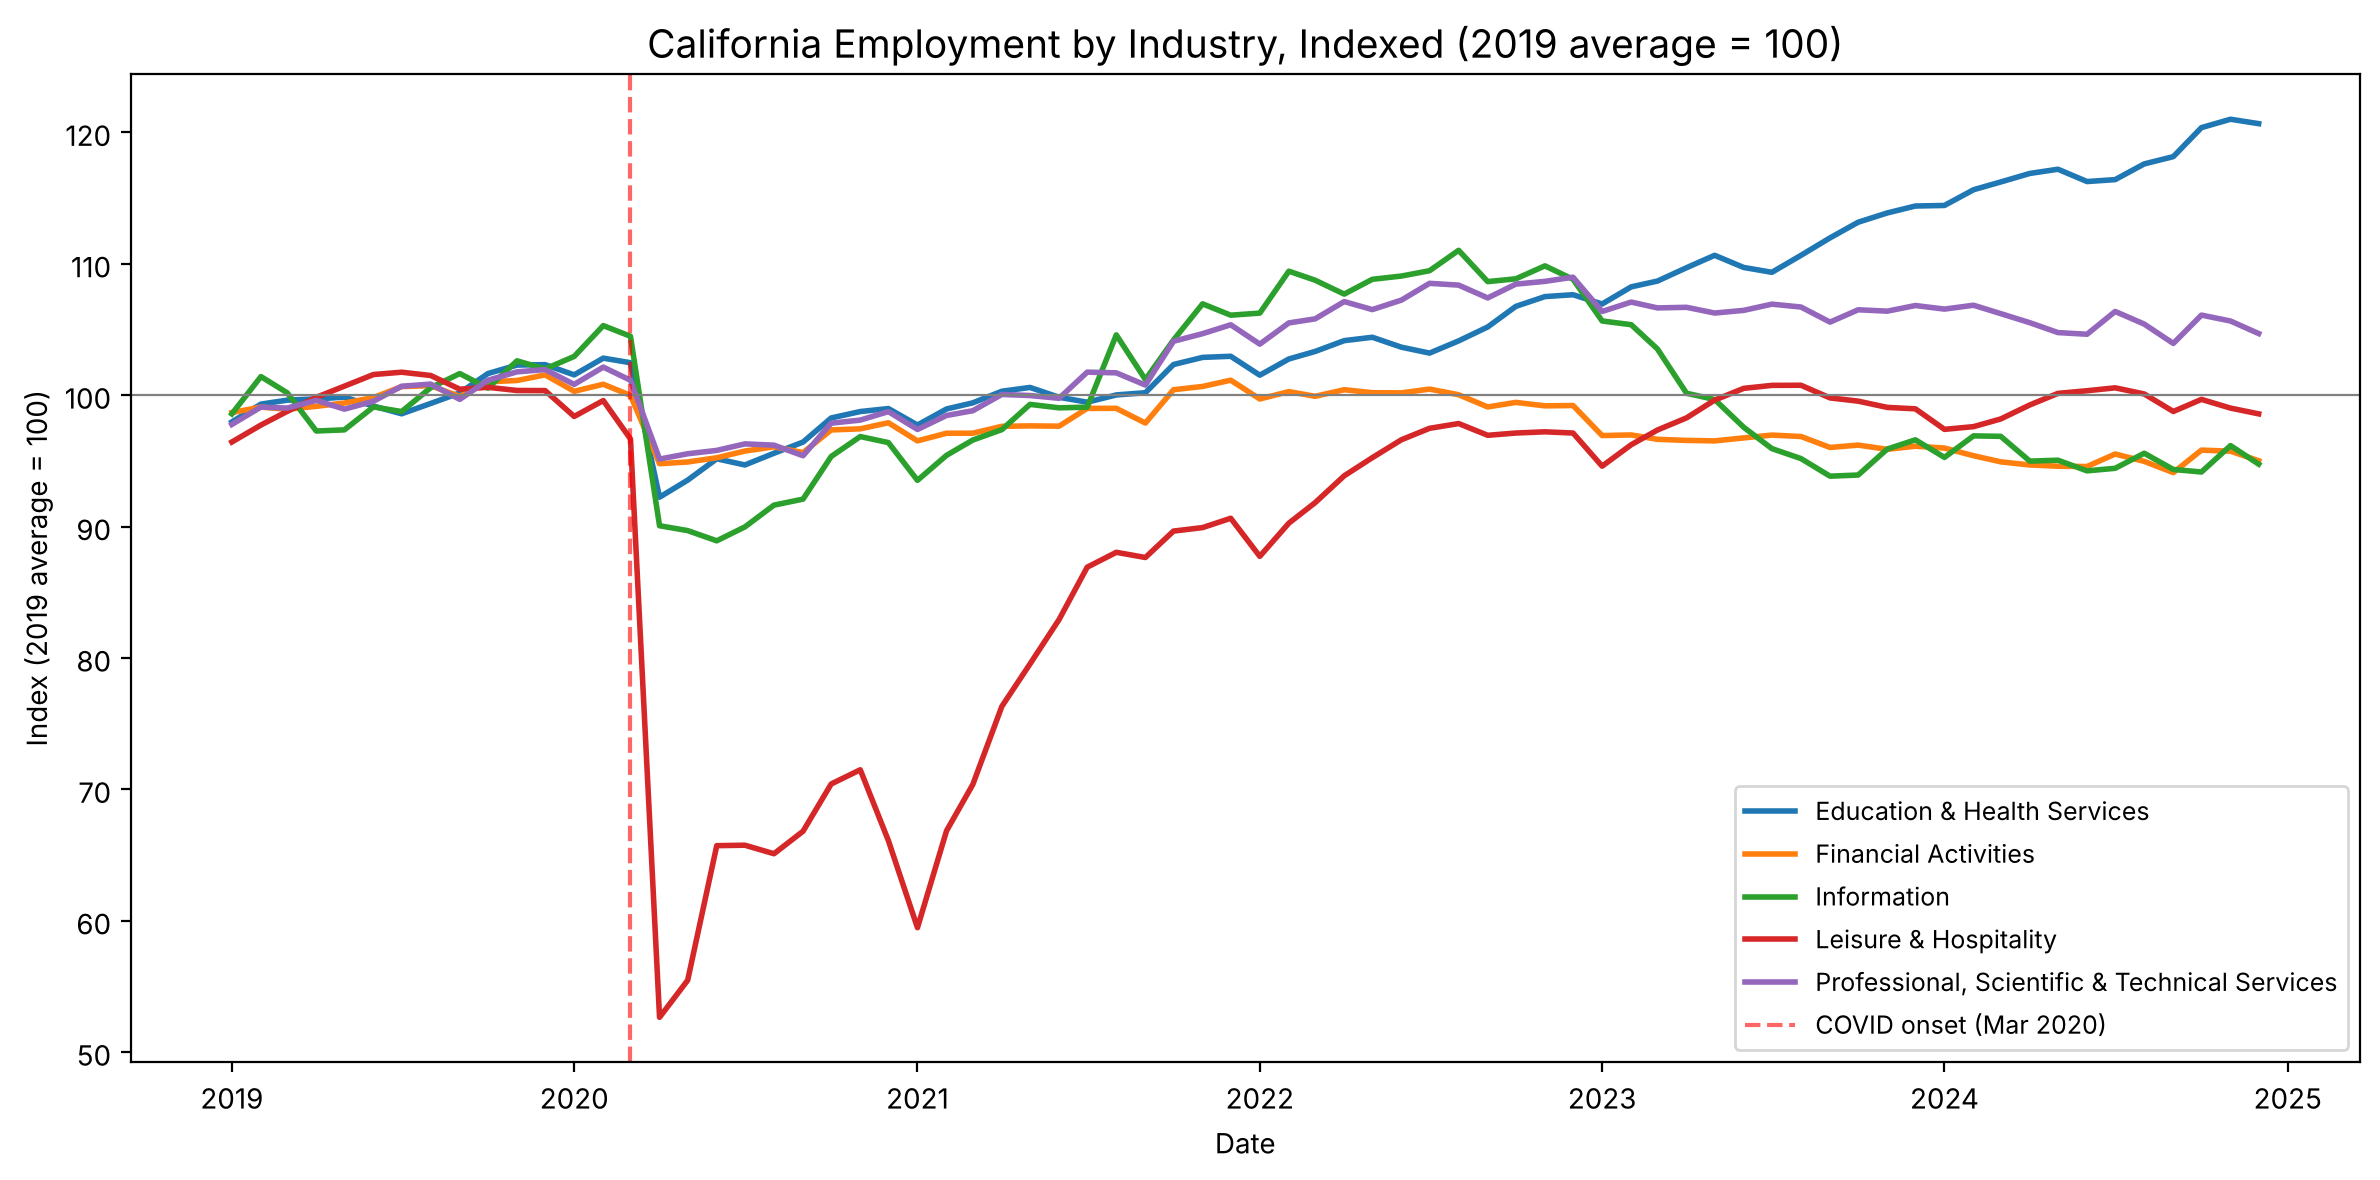

In [10]:
# Index each industry to its 2019 average = 100 so industries of different sizes are comparable
base = df[df["year"] == 2019].groupby("industry")["employment"].mean()
df["index_2019"] = df["employment"] / df["industry"].map(base) * 100

fig, ax = plt.subplots(figsize=(12, 6))
for industry, group in df.sort_values("date").groupby("industry"):
    ax.plot(group["date"], group["index_2019"], label=industry, linewidth=2)
ax.axhline(100, color="gray", linewidth=0.8)
ax.axvline(pd.Timestamp("2020-03-01"), color="red", linestyle="--", alpha=0.6, label="COVID onset (Mar 2020)")
ax.set_title("California Employment by Industry, Indexed (2019 average = 100)", fontsize=14)
ax.set_xlabel("Date")
ax.set_ylabel("Index (2019 average = 100)")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.savefig("charts/employment_trends.png", dpi=150)
plt.show()

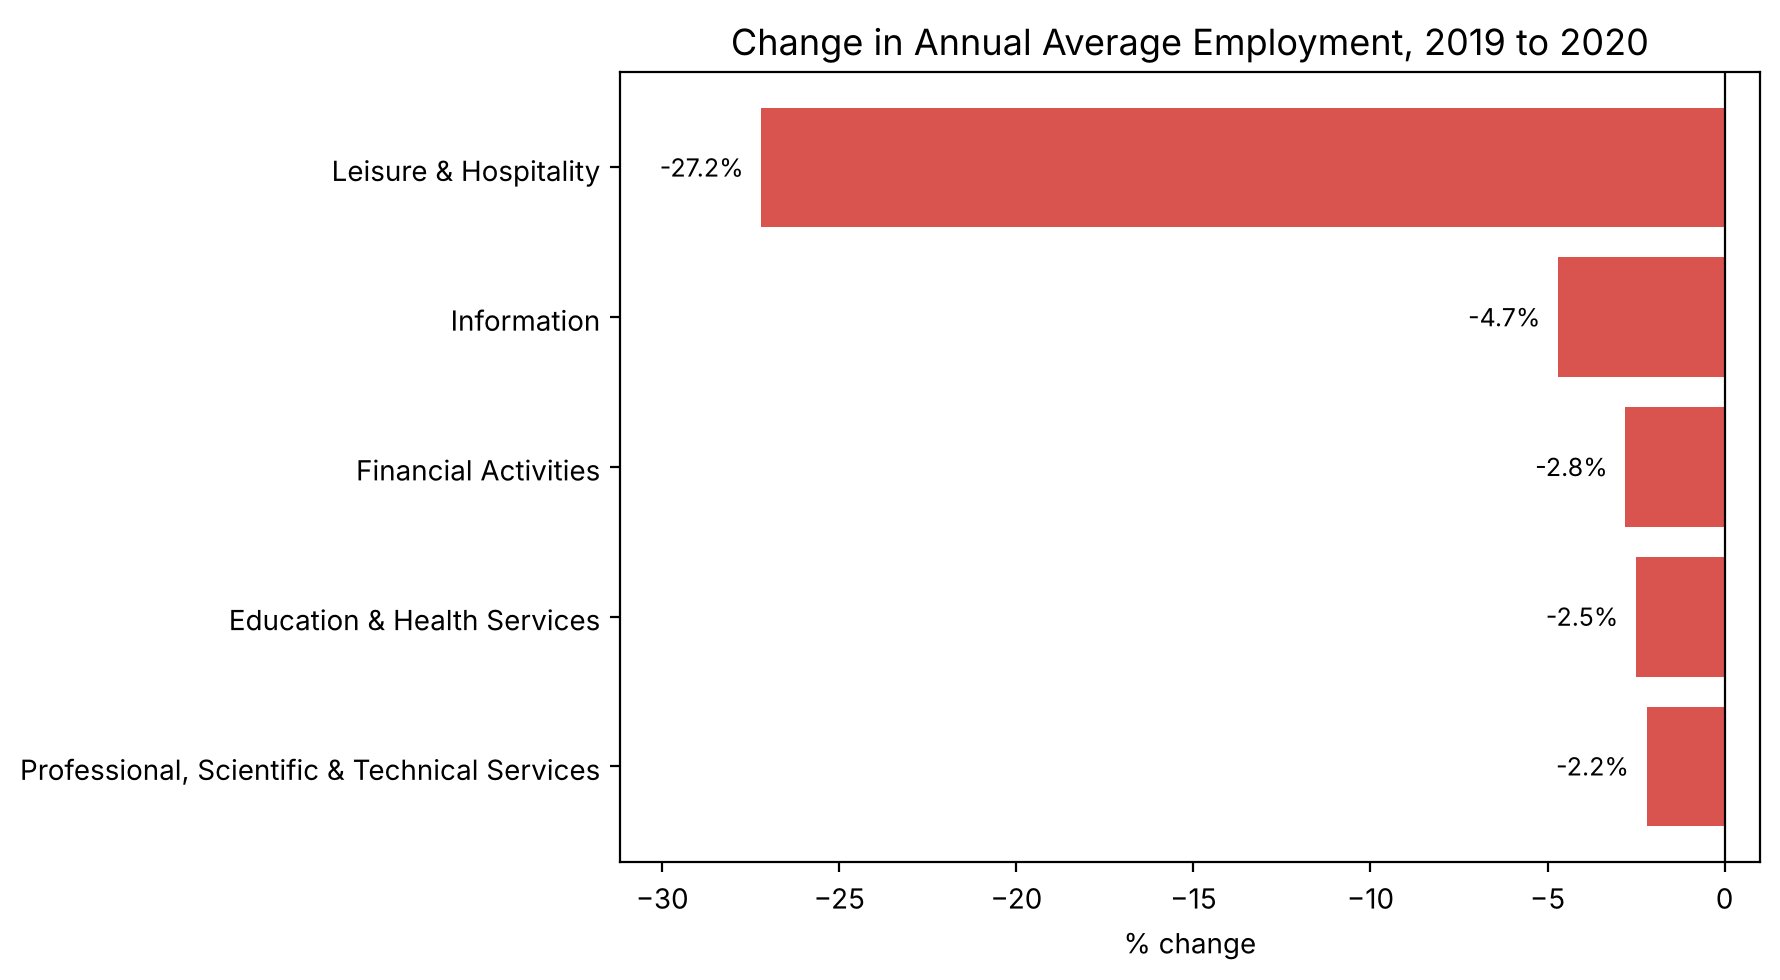

In [11]:
fig, ax = plt.subplots(figsize=(9, 5))
plot_df = q1_result.sort_values("pct_change", ascending=False)
colors = ["#d9534f" if x < 0 else "#5cb85c" for x in plot_df["pct_change"]]
ax.barh(plot_df["industry"], plot_df["pct_change"], color=colors)
for y, x in enumerate(plot_df["pct_change"]):
    ax.text(x - 0.5, y, f"{x}%", va="center", ha="right", fontsize=9)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlim(plot_df["pct_change"].min() - 4, 1)
ax.set_title("Change in Annual Average Employment, 2019 to 2020", fontsize=13)
ax.set_xlabel("% change")
plt.tight_layout()
plt.savefig("charts/pct_change.png", dpi=150)
plt.show()

In [12]:
conn.close()
print("Done")

Done
